# Basic Data Analysis

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import os
import glob

In [2]:
!ls data_hackathon_baywa_re/

ls: data_hackathon_baywa_re/: No such file or directory


In [3]:
# ========================================
folder_path = "../data"
# ========================================


files = sorted(f for f in glob.glob(os.path.join(folder_path, "*_data.xlsx"))
               if not os.path.basename(f).startswith("~$"))

full_idx = pd.date_range("2026-07-01 00:00", "2026-09-30 23:50", freq="10min")
vars_ = ["wind_speed", "wind_direction", "ambient_temperature", "air_pressure", "wind_speed_stddev"]

data = {}
for f in files:
    df = pd.read_excel(f)
    name = df["turbine_name"].iloc[0]          # trust the column, not the file name
    d = df.set_index("timestamp").reindex(full_idx)   # absent rows become NaN rows
    d["row_absent"] = ~full_idx.isin(df["timestamp"])
    data[name] = d
print("Loaded:", list(data))

def period(ts):
    if ts < pd.Timestamp("2026-09-01"): return "train"
    if ts < pd.Timestamp("2026-09-04"): return "hidden_test"
    if ts < pd.Timestamp("2026-09-10"): return "shown_test"
    return "after_test"
periods = pd.Series([period(t) for t in full_idx], index=full_idx)

Loaded: ['H1', 'H2', 'H3', 'H4', 'H5', 'O1', 'O2', 'T1', 'T2', 'T3']


In [4]:
rows = []
for name, d in data.items():
    r = {"turbine": name, "rows_absent": d["row_absent"].sum()}
    for v in vars_:
        r[f"{v}_%NaN"] = round(d[v].isna().mean() * 100, 2)
    r["ws_zero"] = (d["wind_speed"] == 0).sum()
    r["temp_zero"] = (d["ambient_temperature"] == 0).sum()
    r["pressure_constant"] = d["air_pressure"].nunique() <= 1
    rows.append(r)
display(pd.DataFrame(rows).set_index("turbine"))

# Wind speed missing % by period
display(pd.DataFrame({n: d["wind_speed"].isna().groupby(periods).mean() * 100
                      for n, d in data.items()}).T.round(1)
        [["train", "hidden_test", "shown_test", "after_test"]])

,rows_absent,wind_speed_%NaN,wind_direction_%NaN,ambient_temperature_%NaN,air_pressure_%NaN,wind_speed_stddev_%NaN,ws_zero,temp_zero,pressure_constant
turbine,,,,,,,,,
H1,288,4.33,4.33,4.45,3.17,4.33,0,0,False
H2,288,3.05,3.05,3.15,3.05,3.05,0,0,False
H3,288,3.08,3.08,3.12,3.08,3.08,0,0,False
H4,288,3.27,3.27,3.36,3.27,3.27,0,0,False
H5,288,3.08,3.08,3.16,3.08,3.08,0,0,False
O1,288,3.16,3.19,3.28,3.16,100.00,4,0,True
O2,288,2.99,3.00,3.09,2.98,100.00,6,0,True
T1,288,6.59,6.59,6.72,6.39,6.59,3,3,False
T2,288,6.24,6.24,6.45,6.24,6.24,2,2,False


,train,hidden_test,shown_test,after_test
H1,5.9,0.0,0.0,1.6
H2,4.2,0.0,0.0,0.8
H3,4.2,0.0,0.0,1.1
H4,4.4,0.0,0.0,1.3
H5,4.2,0.0,0.0,1.0
O1,4.3,0.0,0.0,1.1
O2,4.2,0.0,0.0,0.7
T1,4.6,100.0,0.0,1.1
T2,4.2,100.0,0.0,0.6
T3,4.0,100.0,0.0,1.3


## Train Test Evaluation

In [5]:
check = []
for name, d in data.items():
    t = d.index[d["test_set"] == True]
    target_nan = d["wind_speed"].isna()
    check.append({
        "turbine": name,
        "test_start": t.min(), "test_end": t.max(), "test_steps": len(t),
        "hidden_NaN_steps": target_nan[(d.index >= "2026-09-01") & (d.index < "2026-09-04")].sum(),
        "shown_NaN_steps": target_nan[(d.index >= "2026-09-04") & (d.index < "2026-09-10")].sum(),
        "first_ts": d.index[~d["row_absent"]].min(), "last_ts": d.index[~d["row_absent"]].max(),
    })
display(pd.DataFrame(check).set_index("turbine"))

# Masks to reuse
idx = full_idx
hidden = (idx >= "2026-09-01") & (idx < "2026-09-04")
shown  = (idx >= "2026-09-04") & (idx < "2026-09-10")
train_dev   = ~hidden & ~shown          # for validation runs
train_final = ~hidden                   # for the final submission fit

,test_start,test_end,test_steps,hidden_NaN_steps,shown_NaN_steps,first_ts,last_ts
turbine,,,,,,,
H1,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
H2,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
H3,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
H4,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
H5,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
O1,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
O2,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
T1,2026-09-01,2026-09-09 23:50:00,1296,432,0,2026-07-01,2026-09-30 23:50:00
T2,2026-09-01,2026-09-09 23:50:00,1296,432,0,2026-07-01,2026-09-30 23:50:00


In [6]:
print(f"Columns are: {data['H1'].columns}") 

Columns are: Index(['turbine_name', 'wind_speed', 'wind_direction', 'ambient_temperature',
       'air_pressure', 'wind_speed_stddev', 'test_set', 'row_absent'],
      dtype='object')


### Are the power curve file all the same

In [7]:
t1_power_path = os.path.join(folder_path, "T1_power_curve.xlsx")
t2_power_path = os.path.join(folder_path, "T2_power_curve.xlsx")
t3_power_path = os.path.join(folder_path, "T3_power_curve.xlsx")

# Are the power curve file all the same
t1_power = pd.read_excel(t1_power_path)
t2_power = pd.read_excel(t2_power_path)
t3_power = pd.read_excel(t3_power_path)


# Check whether all three are identical
# Compare only wind_speed and power
cols = ["wind_speed", "power"]

print("T1 == T2:", t1_power[cols].equals(t2_power[cols]))
print("T1 == T3:", t1_power[cols].equals(t3_power[cols]))
print("T2 == T3:", t2_power[cols].equals(t3_power[cols]))

T1 == T2: True
T1 == T3: True
T2 == T3: True


All the power curve are the same so we can use it as is, and we can maybe interporlate if they are between values.

## Training Data Preparation

In [8]:
def clean(d, stuck_steps=6):
    ''' 
    Set values tp Values to NaN if they are:
    '''
    d = d.copy()
    d["flag"] = ""

    # a) exactly 0.0 m/s average = logger error (temp is also 0 in T rows)
    zero_row = d["wind_speed"] == 0
    d.loc[zero_row, vars_] = np.nan
    d.loc[zero_row, "flag"] += "zero_ws;"

    # b) physically impossible values
    bad_ws = (d["wind_speed"] < 0) | (d["wind_speed"] > 40)
    d.loc[bad_ws, ["wind_speed", "wind_speed_stddev"]] = np.nan
    d.loc[bad_ws, "flag"] += "ws_out_of_range;"
    d.loc[(d["wind_direction"] < 0) | (d["wind_direction"] > 360), "wind_direction"] = np.nan

    # c) stuck sensor: same wind speed for >= 1 hour
    ws_ = d["wind_speed"]
    run_len = ws_.groupby((ws_ != ws_.shift()).cumsum()).transform("size")
    stuck = ws_.notna() & (run_len >= stuck_steps)
    d.loc[stuck, "wind_speed"] = np.nan
    d.loc[stuck, "flag"] += "stuck;"

    # d) constant pressure = placeholder (O park)
    if d["air_pressure"].nunique(dropna=True) <= 1:
        d["air_pressure"] = np.nan
        d["flag"] += "pressure_placeholder;"
    return d

data_clean = {n: clean(d) for n, d in data.items()} 

summary = pd.DataFrame({n: {"zero_ws": d["flag"].str.contains("zero_ws").sum(),
                            "out_of_range": d["flag"].str.contains("ws_out_of_range").sum(),
                            "stuck": d["flag"].str.contains("stuck").sum(),
                            "pressure_placeholder": d["air_pressure"].isna().all()}
                        for n, d in data_clean.items()}).T
display(summary)

,zero_ws,out_of_range,stuck,pressure_placeholder
H1,0,0,0,False
H2,0,0,0,False
H3,0,0,0,False
H4,0,0,0,False
H5,0,0,0,False
O1,4,0,6,True
O2,6,0,0,True
T1,3,0,0,False
T2,2,0,0,False
T3,4,0,0,False


In [9]:
targets = [n for n in data_clean if n.startswith("T")]
refs    = [n for n in data_clean if not n.startswith("T")]

wide = {v: pd.DataFrame({n: data_clean[n][v] for n in data_clean}) for v in vars_}
ws = wide["wind_speed"]

print(f"=== Wind Speed Summary ===")
print("Targets:", targets, "| References:", refs)
display(ws.describe().T.round(2))

=== Wind Speed Summary ===
Targets: ['T1', 'T2', 'T3'] | References: ['H1', 'H2', 'H3', 'H4', 'H5', 'O1', 'O2']


,count,mean,std,min,25%,50%,75%,max
H1,12674.0,5.77,2.16,0.31,4.18,5.72,7.26,15.83
H2,12844.0,5.72,2.22,0.26,4.11,5.61,7.17,17.06
H3,12840.0,6.28,2.41,0.31,4.44,6.33,7.99,17.73
H4,12815.0,5.83,2.21,0.27,4.18,5.80,7.29,20.26
H5,12840.0,6.42,2.42,0.34,4.55,6.43,8.23,17.57
O1,12819.0,6.22,2.58,0.10,4.40,6.00,7.80,22.50
O2,12846.0,6.09,2.69,0.10,4.20,6.00,7.70,21.70
T1,12372.0,5.34,2.15,0.39,3.84,5.11,6.66,17.02
T2,12419.0,5.66,2.26,0.44,4.04,5.50,7.19,16.88
T3,12417.0,5.33,2.08,0.40,3.90,5.19,6.63,16.99


### Dealing with Nan in windspeed

For short missing values,we can maybe interpolate, but for longer gap, it is difficult

In [10]:
raw_t1 = pd.read_excel(os.path.join(folder_path, "T1_data.xlsx"))
print("File timestamp dtype:", raw_t1["timestamp"].dtype)
print("File first rows:\n", raw_t1.head(3))
print("File wind NaN:", raw_t1["wind_speed"].isna().sum(), "of", len(raw_t1))

print("\ndata['T1'] wind NaN:", data["T1"]["wind_speed"].isna().sum(), "of", len(data["T1"]))
print("data['T1'] row_absent True:", data["T1"]["row_absent"].sum())
print("data_clean['T1'] row_absent True:", data_clean["T1"]["row_absent"].sum())

File timestamp dtype: datetime64[ns]
File first rows:
   turbine_name           timestamp  wind_speed  wind_direction  \
0           T1 2026-07-01 00:00:00    4.865286        124.9424   
1           T1 2026-07-01 00:10:00    3.804249        119.1656   
2           T1 2026-07-01 00:20:00    2.952448        142.4393   

   ambient_temperature  air_pressure  wind_speed_stddev  test_set  
0             17.26312      1001.278           0.924104     False  
1             17.42854      1001.276           0.583860     False  
2             17.60092      1001.283           0.950662     False  
File wind NaN: 585 of 12960

data['T1'] wind NaN: 873 of 13248
data['T1'] row_absent True: 288
data_clean['T1'] row_absent True: 288


In [11]:
def gap_table(s):
    """One row per consecutive run of NaN: start, end, length."""
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    g = s.index.to_series()[isna].groupby(run_id[isna]).agg(["first", "last", "size"])
    g.columns = ["start", "end", "steps"]
    g["hours"] = g["steps"] / 6
    return g.reset_index(drop=True)

ws_raw = pd.DataFrame({n: data[n]["wind_speed"] for n in data_clean})
absent = data_clean[targets[0]]["row_absent"]          # same absent rows in every file
all_gaps = []
for n in ws_raw.columns:
    g = gap_table(ws_raw[n])
    g["turbine"] = n
    g["kind"] = np.select(
        [g["start"].ge("2026-09-01") & g["end"].lt("2026-09-04"),
         absent.reindex(g["start"]).values & absent.reindex(g["end"]).values],
        ["hidden_test", "rows_absent_3-4_Aug"],
        "real_gap")
    all_gaps.append(g)
all_gaps = pd.concat(all_gaps, ignore_index=True)

# Count real gaps by length (excludes the hidden test and the absent 3-4 Aug rows)
bins   = [0, 1, 3, 12, 36, 10_000]
labels = ["10 min", "20-30 min (filled)", "40 min-2 h", "2-6 h", "> 6 h"]
real = all_gaps[all_gaps["kind"] == "real_gap"].copy()
real["length"] = pd.cut(real["steps"], bins=bins, labels=labels)
counts = real.pivot_table(index="turbine", columns="length", values="steps",
                          aggfunc="size", fill_value=0, observed=False)
counts["missing steps total"] = real.groupby("turbine")["steps"].sum()
display(counts)

# Every gap longer than 30 min, in time order
long_gaps = all_gaps[all_gaps["steps"] > 3].sort_values(["start", "turbine"]).copy()
long_gaps["hours"] = long_gaps["hours"].round(1)
display(long_gaps[["turbine", "start", "end", "hours", "kind"]])

length,10 min,20-30 min (filled),40 min-2 h,2-6 h,> 6 h,missing steps total
turbine,,,,,,
H1,128,1,0,0,2,286
H2,114,1,0,0,0,116
H3,116,2,0,0,0,120
H4,145,0,0,0,0,145
H5,116,2,0,0,0,120
O1,125,3,0,0,0,131
O2,108,0,0,0,0,108
T1,117,3,0,1,0,153
T2,105,1,0,0,0,107


,turbine,start,end,hours,kind
20,H1,2026-07-13 23:40:00,2026-07-14 09:50:00,10.3,real_gap
21,H1,2026-07-14 10:20:00,2026-07-15 01:50:00,15.7,real_gap
46,H1,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
182,H2,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
297,H3,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
422,H4,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
567,H5,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
687,O1,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
810,O2,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
920,T1,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug


In [12]:
def fill_short_gaps(s, max_gap=3):
    """Linear interpolation only inside gaps of <= max_gap steps (30 min)."""
    isna = s.isna()
    run_len = isna.groupby((isna != isna.shift()).cumsum()).transform("size")
    filled = s.interpolate(method="time", limit_area="inside")
    return s.where(~(isna & (run_len <= max_gap)), filled)

before = ws[refs].isna().sum()

for v in ["wind_speed", "ambient_temperature", "air_pressure", "wind_speed_stddev"]:
    for r in refs:
        wide[v][r] = fill_short_gaps(wide[v][r])

# Also Interpolate wind directions, use sin and cos because the direction is circular (0-360 degrees)
rad = np.deg2rad(wide["wind_direction"][refs])
sin_f = np.sin(rad).apply(fill_short_gaps)
cos_f = np.cos(rad).apply(fill_short_gaps)
wide["wind_direction"][refs] = np.rad2deg(np.arctan2(sin_f, cos_f)) % 360

ws = wide["wind_speed"]
display(pd.DataFrame({"NaN before": before, "NaN after": ws[refs].isna().sum()}))

,NaN before,NaN after
H1,574,444
H2,404,288
H3,408,288
H4,433,288
H5,408,288
O1,429,294
O2,402,288


## Correlation Analysis

Reference can only come from other wind parks, so we want to analyse the correlation and see whcih park provides the best guidance to parkT

Correlation at best lag:


target,T1,T2,T3
ref,,,
H1,0.708,0.719,0.702
H2,0.659,0.718,0.717
H3,0.685,0.772,0.734
H4,0.666,0.730,0.722
H5,0.694,0.764,0.742
O1,0.722,0.789,0.761
O2,0.705,0.791,0.756


Best lag (minutes, negative = target sees the wind first):


target,T1,T2,T3
ref,,,
H1,-30,-30,-30
H2,-20,-30,-30
H3,-30,-30,-30
H4,-20,-30,-30
H5,-30,-30,-30
O1,0,0,0
O2,0,10,0


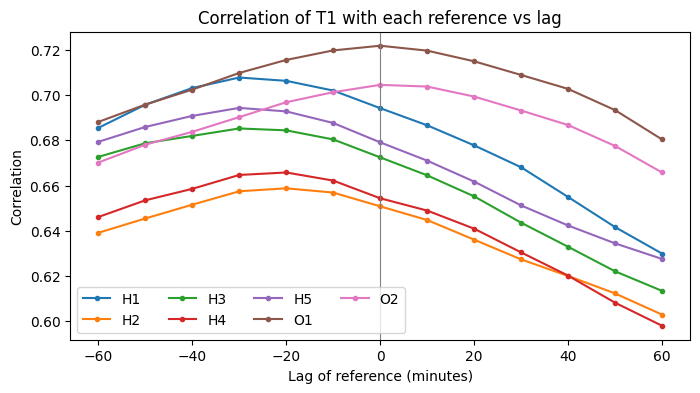

In [13]:
def find_lag(y, x, mask, max_lag=6):
    """Correlation of target y with reference x shifted by -max_lag..+max_lag steps."""
    out = {}
    for L in range(-max_lag, max_lag + 1):
        pair = pd.concat([y, x.shift(L)], axis=1)[mask].dropna()
        out[L * 10] = pair.corr().iloc[0, 1]
    s = pd.Series(out)
    return s.idxmax(), s.max(), s

lag_table, curves = [], {}
for t in targets:
    for r in refs:
        lag_min, c, s = find_lag(ws[t], ws[r], train_dev)
        lag_table.append({"target": t, "ref": r, "lag_min": lag_min, "corr": round(c, 3),
                          "corr_at_0": round(s[0], 3)})
        curves[(t, r)] = s
lag_table = pd.DataFrame(lag_table)

print("Correlation at best lag:")
display(lag_table.pivot(index="ref", columns="target", values="corr"))
print("Best lag (minutes, negative = target sees the wind first):")
display(lag_table.pivot(index="ref", columns="target", values="lag_min"))

# Correlation vs lag for one target, all references
t = targets[0]
fig, ax = plt.subplots(figsize=(8, 4))
for r in refs:
    ax.plot(curves[(t, r)].index, curves[(t, r)].values, marker="o", ms=3, label=r)
ax.axvline(0, color="grey", lw=.8)
ax.set_xlabel("Lag of reference (minutes)"); ax.set_ylabel("Correlation")
ax.set_title(f"Correlation of {t} with each reference vs lag"); ax.legend(ncol=4)
plt.show()

Park O1 and O2 gievs the highest correlation and could be good signal. And for H park, like around 30 minutes later's data seems to have good correlation

## Power Curve

[   0.  584. 1887. 4500.    0.   nan]
Energy of 1 hour at 8 m/s: 2527.0 kWh


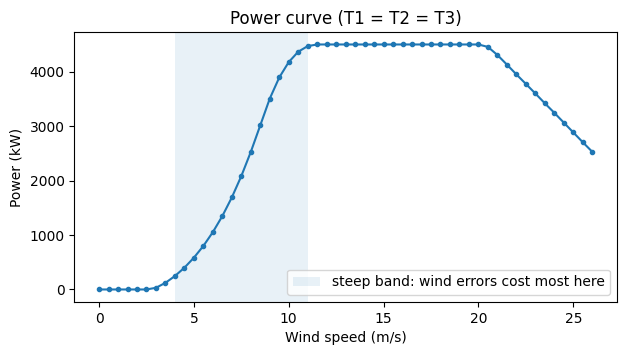

In [14]:
# Power curve: T1 = T2 = T3, so one function for all targets
pc_ws = np.r_[0.0, t1_power["wind_speed"].to_numpy(float)]   # add a 0 m/s -> 0 kW point
pc_kw = np.r_[0.0, t1_power["power"].to_numpy(float)]

def wind_to_power(v):
    """Wind speed (m/s) -> power (kW), linear interpolation between the 0.5 m/s table points."""
    v = np.asarray(v, float)
    p = np.interp(v, pc_ws, pc_kw)
    p[v > pc_ws[-1]] = 0.0          # beyond 26 m/s: turbine off
    p[np.isnan(v)] = np.nan         # missing wind stays missing
    return p

def energy_kwh(v):
    """Energy (kWh) of a series of 10-min wind speeds: power x 1/6 h, summed."""
    return np.nansum(wind_to_power(v)) / 6

# Sanity check
print(wind_to_power([2.0, 5.0, 7.25, 11.5, 30, np.nan]))
print("Energy of 1 hour at 8 m/s:", energy_kwh([8.0] * 6), "kWh")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(pc_ws, pc_kw, marker="o", ms=3)
ax.axvspan(4, 11, alpha=.1, label="steep band: wind errors cost most here")
ax.set_xlabel("Wind speed (m/s)"); ax.set_ylabel("Power (kW)")
ax.set_title("Power curve (T1 = T2 = T3)"); ax.legend()
plt.show()

## Reference Model

Testing out multiple simple baseline regression methods:
Use feature:
- single wind turbine
- OR all wind turbine
- OR the mean

### Evaluation metrics

Notation: $y_t$ = measured wind speed of the target at 10-min step $t$, $\hat{y}_t$ = predicted wind speed,
$P(\cdot)$ = power curve (kW), $N$ = number of evaluated steps.

**Wind speed RMSE** (m/s): typical size of the error at each step; large errors count extra because they are squared.

$$\text{RMSE}_{ws} = \sqrt{\frac{1}{N}\sum_{t=1}^{N}\left(\hat{y}_t - y_t\right)^2}$$

**Wind speed MAE** (m/s): average absolute error at each step.

$$\text{MAE}_{ws} = \frac{1}{N}\sum_{t=1}^{N}\left|\hat{y}_t - y_t\right|$$

**Power RMSE** (kW): same as wind RMSE, but after converting both series through the power curve.
Errors in the steep part of the curve (about 4–11 m/s) weigh most.

$$\text{RMSE}_{P} = \sqrt{\frac{1}{N}\sum_{t=1}^{N}\left(P(\hat{y}_t) - P(y_t)\right)^2}$$

**Energy deviation** (%): error in the **total** energy over the whole period. This is the number the loss claim is based on.

$$\text{Energy deviation} = {E_{pred} - E_{true}}$$

**How they differ**

| | RMSE / MAE | Energy deviation |
|---|---|---|
| Compares | Each 10-min step individually | Totals over the whole period |
| Errors cancel? | No: every error counts, regardless of sign | Yes: over- and under-predictions cancel out |
| Sign | Always ≥ 0 | Negative = energy underestimated, positive = overestimated |
| Detects | How close the prediction tracks the real series | Systematic bias in the total, e.g. too-smooth predictions |

A model can have a low RMSE and still a clear energy deviation: regression predictions are smoother than reality,
and because the power curve is convex in the main operating range, smoothed wind gives too little total energy.
Both are graded, so both are reported.

In [15]:
from sklearn.linear_model import LinearRegression

def shifted_ref(t, r):
    """Reference r, shifted by its best lag for target t (from Step 5)."""
    L = int(lag_table.query("target == @t and ref == @r")["lag_min"].iloc[0] // 10)
    return ws[r].shift(L)

def park_mean(t, members):
    """Average of several references (each lag-shifted), scaled to a common level first."""
    S = pd.DataFrame({r: shifted_ref(t, r) for r in members})
    m = S[train_dev].mean()
    return (S / m * m.mean()).mean(axis=1)

# 3-day blocks over the training period
train_days = full_idx[train_dev].normalize().unique()
blocks = [train_days[i:i + 3] for i in range(0, len(train_days), 3)]
block_id = pd.Series(-1, index=full_idx)
for b, days in enumerate(blocks):
    block_id[full_idx.normalize().isin(days) & train_dev] = b
print(len(blocks), "blocks of 3 days")

def evaluate(X, y):
    """Leave-one-3-day-block-out linear regression; metrics over all blocks."""
    X = X.to_frame() if isinstance(X, pd.Series) else X
    ok = X.notna().all(axis=1) & y.notna()
    pred = pd.Series(np.nan, index=full_idx)
    for b in range(len(blocks)):
        test = (block_id == b) & ok
        fit = train_dev & ok & (block_id != b)
        if test.sum() == 0:
            continue
        m = LinearRegression().fit(X[fit], y[fit])
        pred[test] = m.predict(X[test])
    ev = pred.notna()
    yt, yp = y[ev].values, np.clip(pred[ev].values, 0, None)
    e_true, e_pred = wind_to_power(yt).sum() / 6, wind_to_power(yp).sum() / 6
    return {"ws_rmse": np.sqrt(((yp - yt) ** 2).mean()),
            "ws_mae": np.abs(yp - yt).mean(),
            "p_rmse": np.sqrt(((wind_to_power(yp) - wind_to_power(yt)) ** 2).mean()),
            "energy_dev_%": (e_pred - e_true) / e_true * 100}

h_park = [r for r in refs if r.startswith("H")]
o_park = [r for r in refs if r.startswith("O")]

results = []
for t in targets:
    y = ws[t]
    setups = {f"single {r}": shifted_ref(t, r) for r in refs}
    setups["O park mean"] = park_mean(t, o_park)
    setups["H park mean"] = park_mean(t, h_park)
    setups["all 7 mean"] = park_mean(t, refs)
    setups["all 7 separately"] = pd.DataFrame({r: shifted_ref(t, r) for r in refs})
    for name, X in setups.items():
        results.append({"target": t, "setup": name, **evaluate(X, y)})
results = pd.DataFrame(results)

print("Wind speed RMSE (m/s), lower is better:")
display(results.pivot(index="setup", columns="target", values="ws_rmse").round(3).sort_values(targets[0]))
print("Energy deviation (%), closer to 0 is better:")
display(results.pivot(index="setup", columns="target", values="energy_dev_%").round(1))

28 blocks of 3 days
Wind speed RMSE (m/s), lower is better:


target,T1,T2,T3
setup,,,
all 7 separately,1.294,1.121,1.121
all 7 mean,1.358,1.204,1.178
H park mean,1.453,1.363,1.297
single O1,1.460,1.341,1.301
O park mean,1.467,1.307,1.293
single H1,1.480,1.515,1.426
single O2,1.497,1.335,1.313
single H5,1.518,1.411,1.348
single H3,1.537,1.388,1.365


Energy deviation (%), closer to 0 is better:


target,T1,T2,T3
setup,,,
H park mean,-12.8,-9.6,-11.0
O park mean,-13.1,-8.9,-11.0
all 7 mean,-10.8,-7.1,-8.8
all 7 separately,-10.3,-6.2,-8.3
single H1,-13.8,-12.3,-13.8
single H2,-15.6,-12.3,-12.9
single H3,-14.4,-9.7,-12.2
single H4,-15.4,-11.9,-13.0
single H5,-14.1,-10.0,-11.9


In [16]:
for t in targets:
    X = pd.DataFrame({r: shifted_ref(t, r) for r in refs})
    ok = X.notna().all(axis=1) & ws[t].notna() & train_dev
    m = LinearRegression().fit(X[ok], ws[t][ok])
    print(t, "intercept", round(m.intercept_, 2), "| weights:",
          dict(zip(refs, m.coef_.round(3))))

T1 intercept 0.54 | weights: {'H1': np.float64(0.277), 'H2': np.float64(0.094), 'H3': np.float64(-0.021), 'H4': np.float64(0.006), 'H5': np.float64(0.09), 'O1': np.float64(0.415), 'O2': np.float64(-0.057)}
T2 intercept 0.47 | weights: {'H1': np.float64(-0.018), 'H2': np.float64(0.048), 'H3': np.float64(0.149), 'H4': np.float64(0.055), 'H5': np.float64(0.193), 'O1': np.float64(0.196), 'O2': np.float64(0.22)}
T3 intercept 0.62 | weights: {'H1': np.float64(-0.022), 'H2': np.float64(0.128), 'H3': np.float64(-0.001), 'H4': np.float64(0.135), 'H5': np.float64(0.183), 'O1': np.float64(0.26), 'O2': np.float64(0.09)}


Some feature contribute nearly nothign , when it is close to 0, maybe we could see if it improves prediction results by removing them

In [17]:
def cv_rmse(t, members, positive=True):
    X = pd.DataFrame({r: shifted_ref(t, r) for r in members})
    y = ws[t]
    ok = X.notna().all(axis=1) & y.notna()
    pred = pd.Series(np.nan, index=full_idx)
    for b in range(len(blocks)):
        test = (block_id == b) & ok
        fit = train_dev & ok & (block_id != b)
        if test.sum() == 0:
            continue
        m = LinearRegression(positive=positive).fit(X[fit], y[fit])
        pred[test] = m.predict(X[test])
    ev = pred.notna()
    return np.sqrt(((np.clip(pred[ev], 0, None) - y[ev]) ** 2).mean())

def backward_eliminate(t, members, tol=0.002):
    """Drop references one at a time while CV RMSE gets no worse than +tol m/s."""
    current = list(members)
    best = cv_rmse(t, current)
    history = [{"removed": "-", "refs": len(current), "cv_rmse": best}]
    while len(current) > 1:
        trials = {r: cv_rmse(t, [m for m in current if m != r]) for r in current}
        r_drop = min(trials, key=trials.get)
        if trials[r_drop] > best + tol:
            break
        current.remove(r_drop)
        best = min(best, trials[r_drop])
        history.append({"removed": r_drop, "refs": len(current), "cv_rmse": trials[r_drop]})
    return current, pd.DataFrame(history)

chosen_refs = {}
for t in targets:
    kept, hist = backward_eliminate(t, refs)
    chosen_refs[t] = kept
    print(f"\n{t}: keep {kept}")
    display(hist.round(4))


T1: keep ['H1', 'H2', 'O1']


,removed,refs,cv_rmse
0,-,7,1.2905
1,H3,6,1.2895
2,H4,5,1.2887
3,H5,4,1.2883
4,O2,3,1.2883



T2: keep ['H1', 'H3', 'H5', 'O1', 'O2']


,removed,refs,cv_rmse
0,-,7,1.1197
1,H2,6,1.1193
2,H4,5,1.1203



T3: keep ['H1', 'H2', 'H4', 'H5', 'O1']


,removed,refs,cv_rmse
0,-,7,1.1196
1,H3,6,1.1189
2,O2,5,1.1198


### Use a smoothed wind speed reading as feature to eliminate noise in terms of gusts

Wind RMSE (m/s) by smoothing window:


target,T1,T2,T3
window_min,,,
10,1.288,1.120,1.120
30,1.269,1.102,1.099
60,1.255,1.089,1.087
120,1.248,1.085,1.080
180,1.253,1.094,1.085
360,1.285,1.137,1.120


Energy deviation (%) by smoothing window:


target,T1,T2,T3
window_min,,,
10,-10.2,-6.0,-8.2
30,-9.8,-5.6,-7.8
60,-9.4,-5.3,-7.5
120,-9.2,-5.1,-7.2
180,-9.2,-5.0,-7.2
360,-9.6,-5.4,-7.6


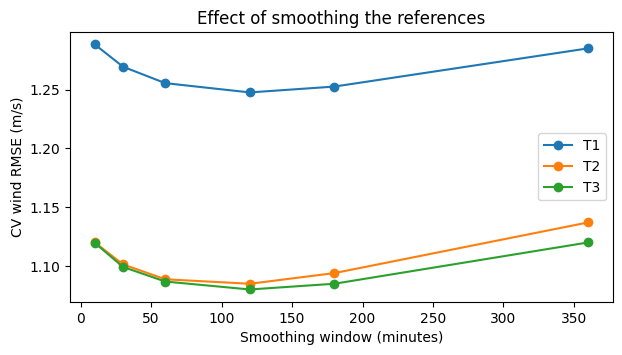

,window_min,ws_rmse,ws_mae,energy_dev_%
target,,,,
T1,120,1.247611,0.938909,-9.162141
T2,120,1.085145,0.824514,-5.084336
T3,120,1.080307,0.818250,-7.191138


In [18]:
def smoothed_ref(t, r, window):
    """Lag-shifted reference, smoothed with a centred rolling mean of `window` steps (10 min each)."""
    x = shifted_ref(t, r)
    if window > 1:
        x = x.rolling(window, center=True, min_periods=window // 2 + 1).mean()
    return x

def cv_eval(t, members, window, positive=True):
    """Leave-one-3-day-block-out regression on smoothed references."""
    X = pd.DataFrame({r: smoothed_ref(t, r, window) for r in members})
    y = ws[t]                                   # target is NOT smoothed: we predict the real 10-min values
    ok = X.notna().all(axis=1) & y.notna()
    pred = pd.Series(np.nan, index=full_idx)
    for b in range(len(blocks)):
        test = (block_id == b) & ok
        fit = train_dev & ok & (block_id != b)
        if test.sum() == 0:
            continue
        m = LinearRegression(positive=positive).fit(X[fit], y[fit])
        pred[test] = m.predict(X[test])
    ev = pred.notna()
    yt, yp = y[ev].values, np.clip(pred[ev].values, 0, None)
    e_true, e_pred = wind_to_power(yt).sum() / 6, wind_to_power(yp).sum() / 6
    return {"ws_rmse": np.sqrt(((yp - yt) ** 2).mean()),
            "ws_mae": np.abs(yp - yt).mean(),
            "energy_dev_%": (e_pred - e_true) / e_true * 100}

windows = [1, 3, 6, 12, 18, 36]      # steps: 1 = no smoothing ... 36 = ~6 h
rows = []
for t in targets:
    for w in windows:
        rows.append({"target": t, "window_min": w * 10, **cv_eval(t, chosen_refs[t], w)})
smooth_res = pd.DataFrame(rows)

print("Wind RMSE (m/s) by smoothing window:")
display(smooth_res.pivot(index="window_min", columns="target", values="ws_rmse").round(3))
print("Energy deviation (%) by smoothing window:")
display(smooth_res.pivot(index="window_min", columns="target", values="energy_dev_%").round(1))

# Plot RMSE vs window
fig, ax = plt.subplots(figsize=(7, 3.5))
for t in targets:
    s = smooth_res[smooth_res.target == t]
    ax.plot(s.window_min, s.ws_rmse, marker="o", label=t)
ax.set_xlabel("Smoothing window (minutes)"); ax.set_ylabel("CV wind RMSE (m/s)")
ax.set_title("Effect of smoothing the references"); ax.legend()
plt.show()

# Best window per target
best_window = smooth_res.loc[smooth_res.groupby("target")["ws_rmse"].idxmin()].set_index("target")
display(best_window)

## could we improve the modelling with T turines weather data

### Given T turbines also not have weather data sometimes, could we use other ones to help

In [19]:
temp = wide["ambient_temperature"]
pres = wide["air_pressure"]          # O1/O2 are NaN: placeholder removed in cleaning
m = train_dev

# 1. How similar are the parks' temperature and pressure?
print("Temperature correlation (train period):")
display(temp[m].corr().loc[targets, refs].round(3))
print("Air pressure correlation (train period, O park has no real pressure):")
display(pres[m].corr().loc[targets, [r for r in refs if r.startswith("H")]].round(3))

# Level differences: pressure offset hints at altitude difference (~8 m per hPa near the ground)
lvl = pd.DataFrame({"mean temp (°C)": temp[m].mean(), "mean pressure (hPa)": pres[m].mean()})
display(lvl.round(2))

# 2. Can a reference park stand in for T? Error when using the H-park average as T's value
h_park = [r for r in refs if r.startswith("H")]
for t in targets:
    for name, s, unit in [("temperature", temp, "°C"), ("pressure", pres, "hPa")]:
        proxy = s[h_park].mean(axis=1)
        d = (s[t] - proxy)[m].dropna()
        print(f"{t} {name}: mean offset {d.mean():+.2f} {unit}, std of difference {d.std():.2f} {unit}")

# 3. Do reference temperature/pressure explain what the current wind model misses?
def model_residuals(t, window=7):
    X = pd.DataFrame({r: smoothed_ref(t, r, window) for r in chosen_refs[t]})
    ok = X.notna().all(axis=1) & ws[t].notna() & m
    reg = LinearRegression(positive=True).fit(X[ok], ws[t][ok])
    pred = pd.Series(np.nan, index=full_idx)
    pred[X.notna().all(axis=1)] = reg.predict(X[X.notna().all(axis=1)])
    return ws[t] - pred

h_temp = temp[h_park].mean(axis=1)
h_pres = pres[h_park].mean(axis=1)
h_turb = wide["wind_speed_stddev"][h_park].mean(axis=1)
air_density = h_pres * 100 / (287.05 * (h_temp + 273.15))
cand = pd.DataFrame({"ref temperature": h_temp, "ref pressure": h_pres,
                     "air density": air_density, "ref turbulence": h_turb,
                     "temp change 3h": h_temp.diff(18),          # warming/cooling ~ day/night stability
                     "pressure change 3h": h_pres.diff(18)})     # passing weather systems

res_corr = pd.DataFrame({t: cand[m].corrwith(model_residuals(t)[m]) for t in targets}).round(3)
print("Correlation with the current model's wind error (residual), per target:")
display(res_corr)

Temperature correlation (train period):


,H1,H2,H3,H4,H5,O1,O2
T1,0.982,0.981,0.978,0.981,0.978,0.978,0.974
T2,0.980,0.979,0.976,0.979,0.976,0.978,0.975
T3,0.981,0.981,0.977,0.981,0.977,0.977,0.974


Air pressure correlation (train period, O park has no real pressure):


,H1,H2,H3,H4,H5
T1,0.981,0.986,0.986,0.989,0.987
T2,0.987,0.993,0.988,0.992,0.994
T3,0.982,0.988,0.990,0.992,0.990


,mean temp (°C),mean pressure (hPa)
H1,18.61,990.72
H2,18.45,988.68
H3,18.64,986.01
H4,18.39,990.32
H5,18.64,985.73
O1,18.84,NaN
O2,18.14,NaN
T1,19.19,998.00
T2,19.45,998.82
T3,19.32,1000.09


T1 temperature: mean offset +0.64 °C, std of difference 0.84 °C
T1 pressure: mean offset +9.72 hPa, std of difference 0.79 hPa
T2 temperature: mean offset +0.92 °C, std of difference 0.90 °C
T2 pressure: mean offset +10.53 hPa, std of difference 0.57 hPa
T3 temperature: mean offset +0.77 °C, std of difference 0.85 °C
T3 pressure: mean offset +11.81 hPa, std of difference 0.69 hPa
Correlation with the current model's wind error (residual), per target:


,T1,T2,T3
ref temperature,0.089,0.024,0.017
ref pressure,0.077,-0.030,-0.015
air density,-0.054,-0.031,-0.020
ref turbulence,0.024,0.101,0.063
temp change 3h,-0.017,0.109,0.063
pressure change 3h,0.000,-0.075,-0.044


### Forward Selection to select the features

In [20]:
from scipy.optimize import lsq_linear

WINDOW = 13                      # 130 min, centred (odd number of steps keeps it symmetric)
h_park = [r for r in refs if r.startswith("H")]

class BoundedLinear:
    """Linear regression where reference weights are >= 0 and all other coefficients are free."""
    def __init__(self, nonneg_cols):
        self.nonneg_cols = set(nonneg_cols)
    def fit(self, X, y):
        self.cols = list(X.columns)
        A = np.column_stack([np.ones(len(X)), X.values])
        lb = [-np.inf] + [0 if c in self.nonneg_cols else -np.inf for c in self.cols]
        sol = lsq_linear(A, y.values, bounds=(lb, [np.inf] * len(lb)))
        self.intercept_, self.coef_ = sol.x[0], sol.x[1:]
        return self
    def predict(self, X):
        return self.intercept_ + X[self.cols].values @ self.coef_

def build_features(t, window=WINDOW):
    F = pd.DataFrame(index=full_idx)
    for r in chosen_refs[t]:
        F[f"ws_{r}"] = smoothed_ref(t, r, window)
    ref_cols = [f"ws_{r}" for r in chosen_refs[t]]
    ref_avg = F[ref_cols].mean(axis=1)
    hour = full_idx.hour + full_idx.minute / 60
    F["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    F["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    F["ref_x_hour_sin"] = ref_avg * F["hour_sin"]          # slope changes with time of day
    F["ref_x_hour_cos"] = ref_avg * F["hour_cos"]
    rad = np.deg2rad(wide["wind_direction"][refs])
    F["dir_sin"] = np.sin(rad).mean(axis=1)
    F["dir_cos"] = np.cos(rad).mean(axis=1)
    F["ref_x_dir_sin"] = ref_avg * F["dir_sin"]            # slope changes with wind direction
    F["ref_x_dir_cos"] = ref_avg * F["dir_cos"]
    F["turbulence"] = wide["wind_speed_stddev"][h_park].mean(axis=1).rolling(window, center=True, min_periods=1).mean()
    F["temp_change_3h"] = wide["ambient_temperature"][h_park].mean(axis=1).diff(18)
    return F, ref_cols

def cv_score(t, F, cols, ref_cols):
    y = ws[t]
    ok = F[cols].notna().all(axis=1) & y.notna()
    pred = pd.Series(np.nan, index=full_idx)
    for b in range(len(blocks)):
        test = (block_id == b) & ok
        fit = train_dev & ok & (block_id != b)
        if test.sum() == 0:
            continue
        m = BoundedLinear(ref_cols).fit(F.loc[fit, cols], y[fit])
        pred[test] = m.predict(F.loc[test, cols])
    ev = pred.notna()
    yt, yp = y[ev].values, np.clip(pred[ev].values, 0, None)
    e_true, e_pred = wind_to_power(yt).sum() / 6, wind_to_power(yp).sum() / 6
    return {"ws_rmse": np.sqrt(((yp - yt) ** 2).mean()),
            "ws_mae": np.abs(yp - yt).mean(),
            "energy_dev_%": (e_pred - e_true) / e_true * 100}

candidates = {
    "hour":           ["hour_sin", "hour_cos"],
    "ref_x_hour":     ["ref_x_hour_sin", "ref_x_hour_cos"],
    "direction":      ["dir_sin", "dir_cos"],
    "ref_x_dir":      ["ref_x_dir_sin", "ref_x_dir_cos"],
    "turbulence":     ["turbulence"],
    "temp_change_3h": ["temp_change_3h"],
}

def forward_select(t, min_gain=0.002):
    F, ref_cols = build_features(t)
    cols, remaining = list(ref_cols), dict(candidates)
    best = cv_score(t, F, cols, ref_cols)
    history = [{"step": 0, "added": "references only", **best}]
    while remaining:
        trials = {g: cv_score(t, F, cols + c, ref_cols) for g, c in remaining.items()}
        g = min(trials, key=lambda k: trials[k]["ws_rmse"])
        gain = (best["ws_rmse"] - trials[g]["ws_rmse"]) / best["ws_rmse"]
        print(f"  {t} step {len(history)}: " + ", ".join(
            f"{k}={v['ws_rmse']:.3f}" for k, v in sorted(trials.items(), key=lambda kv: kv[1]["ws_rmse"])))
        if gain < min_gain:
            print(f"  stop: best gain {gain * 100:.2f}% < {min_gain * 100:.1f}%")
            break
        cols += remaining.pop(g)
        best = trials[g]
        history.append({"step": len(history), "added": g, **best})
    return cols, ref_cols, pd.DataFrame(history).set_index("step")

selected = {}
for t in targets:
    print(f"\n===== {t} =====")
    cols, ref_cols, hist = forward_select(t)
    selected[t] = (cols, ref_cols)
    display(hist.round(3))


===== T1 =====
  T1 step 1: ref_x_dir=1.205, direction=1.209, ref_x_hour=1.243, hour=1.245, temp_change_3h=1.247, turbulence=1.250
  T1 step 2: ref_x_hour=1.201, turbulence=1.202, hour=1.203, temp_change_3h=1.204, direction=1.206
  T1 step 3: temp_change_3h=1.200, hour=1.201, turbulence=1.201, direction=1.203
  stop: best gain 0.08% < 0.2%


,added,ws_rmse,ws_mae,energy_dev_%
step,,,,
0,references only,1.247,0.939,-9.132
1,ref_x_dir,1.205,0.905,-8.071
2,ref_x_hour,1.201,0.901,-7.974



===== T2 =====
  T2 step 1: turbulence=1.069, ref_x_hour=1.074, temp_change_3h=1.074, hour=1.078, ref_x_dir=1.082, direction=1.085
  T2 step 2: temp_change_3h=1.065, ref_x_hour=1.069, ref_x_dir=1.069, direction=1.069, hour=1.070
  T2 step 3: ref_x_hour=1.067, direction=1.067, ref_x_dir=1.067, hour=1.068
  stop: best gain -0.17% < 0.2%


,added,ws_rmse,ws_mae,energy_dev_%
step,,,,
0,references only,1.083,0.823,-5.037
1,turbulence,1.069,0.809,-5.123
2,temp_change_3h,1.065,0.805,-5.057



===== T3 =====
  T3 step 1: turbulence=1.073, temp_change_3h=1.076, ref_x_hour=1.076, hour=1.079, direction=1.082, ref_x_dir=1.083
  T3 step 2: temp_change_3h=1.071, ref_x_hour=1.074, hour=1.074, direction=1.074, ref_x_dir=1.076
  stop: best gain 0.19% < 0.2%


,added,ws_rmse,ws_mae,energy_dev_%
step,,,,
0,references only,1.080,0.817,-7.158
1,turbulence,1.073,0.810,-7.034
